[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/22_retina_responses.ipynb)

# Retina: the recorded responses the encoders were fitted to

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Load the recordings of the flashed-natural-image adaptation dataset (Lorenzi et al.), to which the retina encoders of notebooks 12 to 21 were fitted, and plot the responses of a few retinal ganglion cells. Each clip shows an adapting image for 400 ms, then a natural image for 400 ms; the responses are spike counts in 25 ms bins, one trial per training clip and 30 repeats per test clip.

* **Requirements**: the recordings, one `<cell>.npz` per cell (on this machine in `/home/steeve/steeve/idv/datasets/proj_multigeom/open-retina-multigeom/lorenzi_adaptation/data/`, not public), and `openretina` (`open-retina-multigeom`) for the cell types.

* **Time**: a few seconds.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [ ]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.datasets": {"list_lorenzi_cells": [], "load_lorenzi_cell": []},
        "multigeom.plotting": {"plot_cell_counts": [], "plot_cell_responses": []},
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 3.61 s, sys: 143 ms, total: 3.75 s
Wall time: 1.34 s


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: where the recordings are, the cells shown, the test clip, and where the figures go.

<details><summary>Details</summary>

* `list_lorenzi_cells` lists the recorded cells with their experiment and type (open-retina's table), `load_lorenzi_cell` loads one cell's stimulus frames and spike counts; `plot_cell_counts` and `plot_cell_responses` draw the figures.

</details>

In [ ]:
%%time

import os
from pathlib import Path

import matplotlib.pyplot as plt

# move to the repository root (the folder containing environment.yml): assets/ is
# written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.datasets import list_lorenzi_cells, load_lorenzi_cell
from multigeom.plotting import plot_cell_counts, plot_cell_responses

# the parameters of this notebook
PARAMS = {
    # the recordings: one <cell>.npz per retinal ganglion cell
    "data_dir": (
        "/home/steeve/steeve/idv/datasets/proj_multigeom/open-retina-multigeom/"
        "lorenzi_adaptation/data"
    ),
    # the cells shown: the two reference cells of notebooks 12 to 21 and another cell
    # of each type
    "cells": ["176-exp7", "686-exp4", "17-exp5", "418-exp5"],
    # the test clip shown (clip 0: after a grey adapting image)
    "clip": 0,
    # where the figures are saved, and their resolution in the file and on screen
    "figure_dir": "assets/figures/retina/responses",
    "file_dpi": 200,
    "screen_dpi": 100,
}

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
CPU times: user 345 μs, sys: 15 μs, total: 360 μs
Wall time: 432 μs


## 2. The recorded cells

One file per retinal ganglion cell, from 4 experiments (exp4 to exp7); their functional types come from open-retina's metadata table. The figure is saved to `assets/figures/retina/responses/cell_counts.png`.

487 cells
CPU times: user 1.42 s, sys: 1.84 s, total: 3.27 s
Wall time: 771 ms


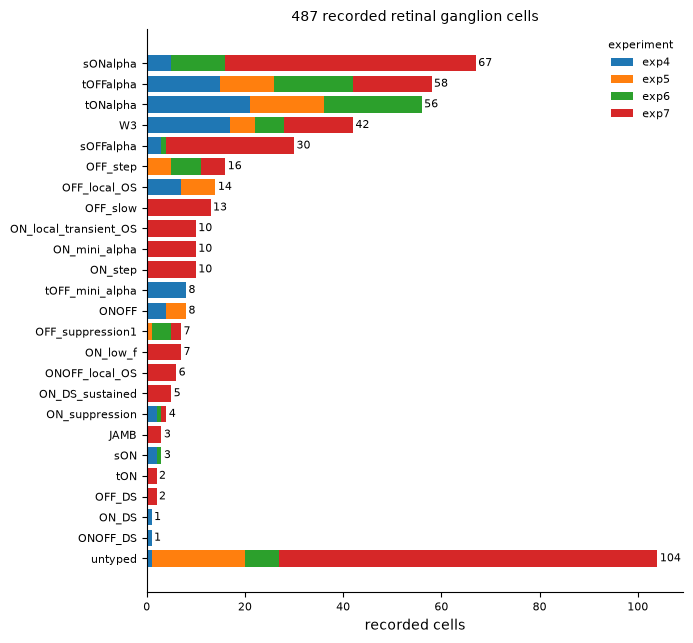

In [ ]:
%%time

# the cells, per type and experiment
rows = list_lorenzi_cells(Path(PARAMS["data_dir"]))
print(len(rows), "cells")

# the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, counts = plot_cell_counts(rows, PARAMS)
fig.savefig(figure_dir / "cell_counts.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")

## 3. The responses of a few cells

One row per cell: the adapting and natural images of the test clip; the spike counts of each of its repeats; their mean firing rate ± standard error over the repeats; and the mean rate over all the training clips, one trial each. The adapting image is on for the first 400 ms (shaded), the natural image for the next 400 ms. The figure is saved to `assets/figures/retina/responses/cell_responses.png`.

<details><summary>Details</summary>

* **Units.** Counts are spikes per 25 ms bin; rates are counts divided by 25 ms.
* **Images.** Each cell saw the stimulus at its own resolution (30 x 30 pixels at 21 µm per pixel for exp4 to exp6, 40 x 40 at 15.6 µm for exp7), drawn around its grey level.
* **Training clips** all start from a grey adapting image (the first frames of the bank), so their mean rate shows the response to grey then to a natural image.

</details>

176-exp7: W3, 3185 training clips, 25 test clips x 30 repeats
686-exp4: W3, 3180 training clips, 30 test clips x 30 repeats
17-exp5: tOFFalpha, 3180 training clips, 30 test clips x 30 repeats
418-exp5: tOFFalpha, 3180 training clips, 30 test clips x 30 repeats


CPU times: user 685 ms, sys: 21.9 ms, total: 707 ms
Wall time: 707 ms


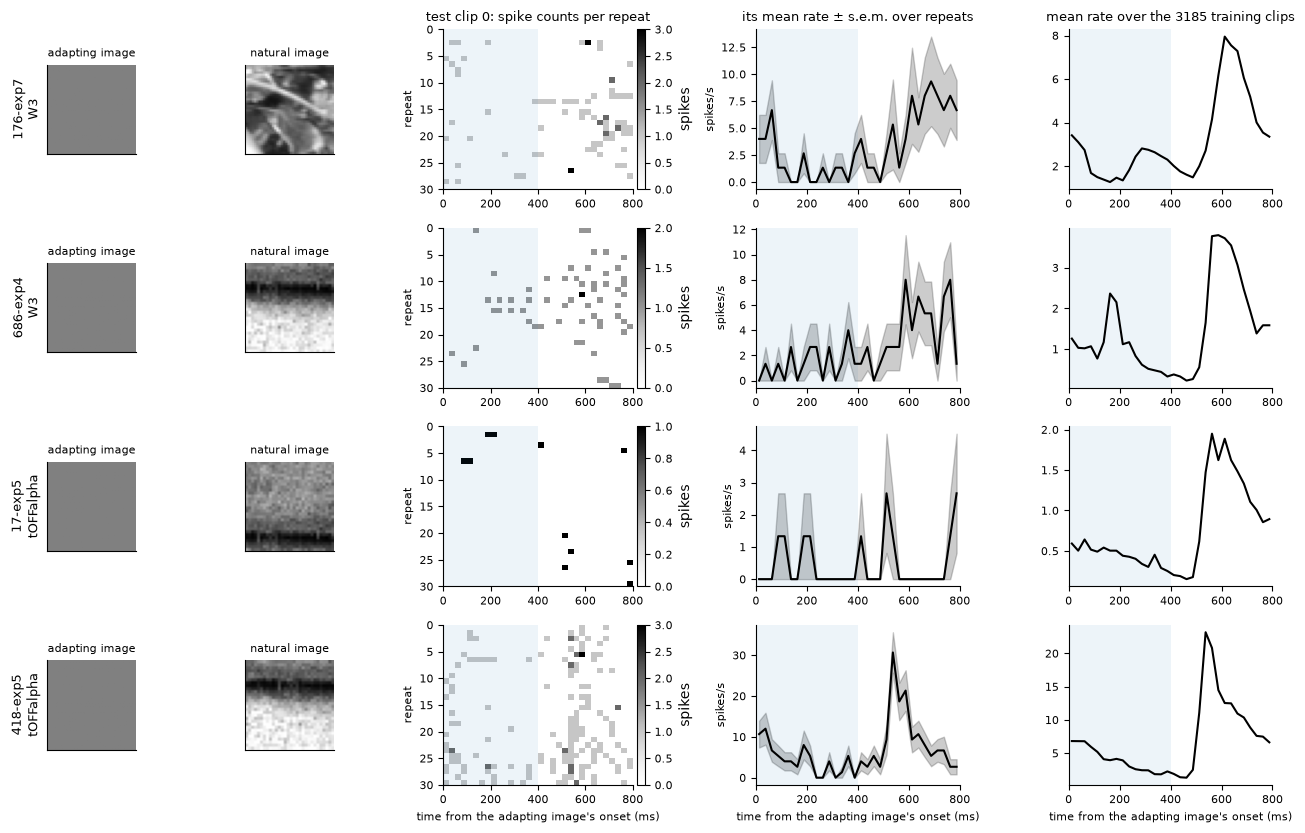

In [ ]:
%%time

# the recordings of the cells, then the figure, also saved
cells = [load_lorenzi_cell(Path(PARAMS["data_dir"]), cell) for cell in PARAMS["cells"]]
for cell in cells:
    print(
        f"{cell.cell}: {cell.metadata.get('cell_type') or 'untyped'},"
        f" {len(cell.train_counts)} training clips,"
        f" {cell.test_counts.shape[0]} test clips x {cell.test_counts.shape[1]} repeats"
    )
fig, rates = plot_cell_responses(cells, PARAMS, clip=PARAMS["clip"])
fig.savefig(
    figure_dir / "cell_responses.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

## 4. Conclusion

(written after the run)